# E2：Joint 表达表示实验

总维度固定的欧氏 + Poincaré 联合 AE，检验融合是否优于单几何。

本 notebook 独立使用一张 GPU。请选用独立 kernel，从第一格顺序运行。默认留出 1/2/3，每折 5 seeds、100 epochs；三组同时运行时使用相同配置。

当前只做表示验证，输出冻结编码器与评价；后续才将得到验证的表示接入 DeepSpatial UOT。详细指标与实验边界见 [README](README.md)。

In [8]:
# 必须在导入 torch 前运行；换卡时重启本 notebook 的 kernel。
import os
import sys
GPU_ID = "0"  # 物理 GPU 编号；调度器已限制可见卡时可设 None，保留分配。
if "torch" in sys.modules:
    raise RuntimeError("当前 kernel 已导入 torch，请重启 kernel 后从第一格运行。")
if GPU_ID is not None:
    os.environ["CUDA_VISIBLE_DEVICES"] = GPU_ID
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
print("CUDA_VISIBLE_DEVICES =", os.environ.get("CUDA_VISIBLE_DEVICES", "scheduler/default"))


RuntimeError: 当前 kernel 已导入 torch，请重启 kernel 后从第一格运行。

In [2]:
from pathlib import Path
from copy import deepcopy
# 支持从仓库根目录、MMDeepSpatial 或其子目录启动；也支持仅上传 MMDeepSpatial。
PROJECT = next((candidate for parent in (Path.cwd(), *Path.cwd().parents)
                for candidate in (parent, parent / "MMDeepSpatial")
                if (candidate / "mmdeepspatial/experiment.py").is_file()), None)
if PROJECT is None:
    raise FileNotFoundError("请在 MMDeepSpatial 或其父目录打开 notebook。")
sys.path.insert(0, str(PROJECT))
from mmdeepspatial.experiment import DEFAULT_CONFIG, run_experiment
from mmdeepspatial.data import input_paths
import pandas as pd
print("MMDeepSpatial:", PROJECT)


MMDeepSpatial: /3250608056/code/DeepSpatial/MMDeepSpatial


## 统一配置

三组的划分、种子、维度、训练和 probe 参数必须保持一致。`log1p` 适用于非负未 log 表达；已 log 或 scaled 的数据统一改 `identity`。首次检查可三组同时改成 holdout `[2]`、seed `[0]`、epochs `2`，正式运行使用全新输出目录。

In [3]:
ARM = "E2"
DATA_GLOB = str(PROJECT.parent / "data/merfish_mouse_hypothalamus/**/merfish_[0-4].h5ad")
OUTPUT_ROOT = PROJECT / "outputs/representations_v2"
HOLDOUTS = [1, 2, 3]  # 文件自然排序后的零起始编号，必须为中间切片
SEEDS = [42, 0, 1, 2, 3]
EPOCHS = 100
MAX_TANGENT_RADIUS = 1.5  # sqrt(c) * tangent norm 的平滑上限
DIAGNOSTIC_ALPHAS = [0.25, 0.75]  # 仅作诊断，不在测试切片选择最优值
DIM = 32  # E0=32E；E1=32H；E2=16E+16H；AE 参数量相同
LABEL_KEY = "cell_class"
LAYER = None  # 例如 "counts"；None 读取 X
TRANSFORM = "log1p"  # 已经 log / 标准化的 X 改成 "identity"
E0_METHOD = "ae"  # E0 可另跑 "pca"；E1/E2 忽略此值
DEVICE = "cuda"  # 本 kernel 可见的单卡；CPU 冒烟测试用 "cpu"

CONFIG = deepcopy(DEFAULT_CONFIG)
CONFIG.update(input_glob=DATA_GLOB, output_root=str(OUTPUT_ROOT), holdouts=HOLDOUTS,
              seeds=SEEDS, epochs=EPOCHS, dim=DIM, label_key=LABEL_KEY, layer=LAYER,
              transform=TRANSFORM, e0_method=E0_METHOD, device=DEVICE,
              max_tangent_radius=MAX_TANGENT_RADIUS, diagnostics=True,
              diagnostic_alphas=DIAGNOSTIC_ALPHAS)
# 其他固定参数均来自 DEFAULT_CONFIG；改动时三个 notebook 同步修改。
# 例如 CONFIG.update(batch_size=512, curvature=1.0, fusion_alpha=0.5)
CONFIG


{'input_glob': '/3250608056/code/DeepSpatial/data/merfish_mouse_hypothalamus/**/merfish_[0-4].h5ad',
 'output_root': '/3250608056/code/DeepSpatial/MMDeepSpatial/outputs/representations_v2',
 'holdouts': [1, 2, 3],
 'seeds': [42, 0, 1, 2, 3],
 'label_key': 'cell_class',
 'layer': None,
 'transform': 'log1p',
 'n_genes': 0,
 'rare_fraction': 0.05,
 'dim': 32,
 'hidden': 128,
 'epochs': 100,
 'batch_size': 512,
 'lr': 0.001,
 'weight_decay': 1e-05,
 'grad_clip': 5.0,
 'curvature': 1.0,
 'fusion_alpha': 0.5,
 'log_every': 10,
 'e0_method': 'ae',
 'device': 'cuda',
 'cpu_threads': 4,
 'retrieval_ks': [1, 5, 15],
 'query_chunk': 128,
 'reference_chunk': 2048,
 'coverage_quantile': 0.95,
 'coverage_calibration_max': 2048,
 'probe_c': 1.0,
 'probe_class_weight': 'balanced',
 'probe_max_iter': 2000,
 'shuffled_probe': False,
 'max_tangent_radius': 1.5,
 'diagnostics': True,
 'diagnostic_alphas': [0.25, 0.75]}

In [4]:
paths = input_paths(CONFIG["input_glob"])
display(pd.DataFrame({"slice_index": range(len(paths)), "file": [str(p) for p in paths],
                      "used_as_holdout": [i in HOLDOUTS for i in range(len(paths))]}))
print("总训练任务:", len(HOLDOUTS) * len(SEEDS))
print("数据预处理、编码器和 probe 均在隐藏切片评价前冻结。")


,slice_index,file,used_as_holdout
0,0,/3250608056/code/DeepSpatial/data/merfish_mous...,False
1,1,/3250608056/code/DeepSpatial/data/merfish_mous...,True
2,2,/3250608056/code/DeepSpatial/data/merfish_mous...,True
3,3,/3250608056/code/DeepSpatial/data/merfish_mous...,True
4,4,/3250608056/code/DeepSpatial/data/merfish_mous...,False


总训练任务: 15
数据预处理、编码器和 probe 均在隐藏切片评价前冻结。


## 训练与评价

每组运行 3 个留出切片 × 5 个 seed，共 15 次编码器训练。输出到新的 `representations_v2`，保留上一轮结果。

双曲映射先做平滑径向压缩；训练记录原始切空间范数、球半径分布和接近平滑上限的比例。E0 加 L2/余弦诊断，E1 加角度诊断，E2 加分支独立 probe 与固定权重诊断。所有 probe 与距离标定都在读取测试切片前完成。

这些仍是探索性表示实验；本轮调参已参考上一轮相同切片，最终结论需要独立样本验证。


In [5]:
results = run_experiment(ARM, CONFIG)
display(results[["arm", "holdout", "seed", "rare_macro_auprc", "rare_macro_f1",
                 "rare_macro_retrieval_hit_at_5", "rare_macro_knn_purity_at_5",
                 "common_macro_f1", "overall_accuracy", "trainable_parameters"]])


E2 | cuda | 5 slices | output=/3250608056/code/DeepSpatial/MMDeepSpatial/outputs/representations_v2/E2_ae
Start E2 holdout=1 seed=42 train=(22760, 155)
E2 seed=42 epoch=1/100 mse=0.88423 boundary=0.000%
E2 seed=42 epoch=10/100 mse=0.50620 boundary=0.000%
E2 seed=42 epoch=20/100 mse=0.46687 boundary=0.000%
E2 seed=42 epoch=30/100 mse=0.45018 boundary=0.000%
E2 seed=42 epoch=40/100 mse=0.44007 boundary=0.000%
E2 seed=42 epoch=50/100 mse=0.43249 boundary=0.000%
E2 seed=42 epoch=60/100 mse=0.42648 boundary=0.000%
E2 seed=42 epoch=70/100 mse=0.42112 boundary=0.000%
E2 seed=42 epoch=80/100 mse=0.41642 boundary=0.000%
E2 seed=42 epoch=90/100 mse=0.41241 boundary=0.000%
E2 seed=42 epoch=100/100 mse=0.40889 boundary=0.000%
 rare_macro_auprc  rare_macro_f1  overall_accuracy
         0.680671       0.627738          0.896887
Start E2 holdout=1 seed=0 train=(22760, 155)
E2 seed=0 epoch=1/100 mse=0.89637 boundary=0.000%
E2 seed=0 epoch=10/100 mse=0.50357 boundary=0.000%
E2 seed=0 epoch=20/100 mse=0

,arm,holdout,seed,rare_macro_auprc,rare_macro_f1,rare_macro_retrieval_hit_at_5,rare_macro_knn_purity_at_5,common_macro_f1,overall_accuracy,trainable_parameters
0,E2,1,42,0.680671,0.627738,0.725057,0.551126,0.923708,0.896887,48315
1,E2,1,0,0.678389,0.637060,0.758453,0.544497,0.915936,0.893288,48315
2,E2,1,1,0.696299,0.646647,0.746142,0.555786,0.919305,0.898146,48315
3,E2,1,2,0.660475,0.619366,0.717768,0.536142,0.914784,0.895627,48315
4,E2,1,3,0.711627,0.639772,0.735084,0.542910,0.926223,0.904265,48315
5,E2,2,42,0.765702,0.618360,0.792111,0.591064,0.910231,0.888458,48315
6,E2,2,0,0.786391,0.614212,0.757017,0.569385,0.915204,0.884408,48315
7,E2,2,1,0.778133,0.609132,0.759980,0.578135,0.916031,0.886939,48315
8,E2,2,2,0.755011,0.590597,0.832332,0.587562,0.904130,0.877320,48315
9,E2,2,3,0.782428,0.631114,0.767506,0.564408,0.904030,0.881201,48315


,rare_macro_auprc,rare_macro_f1,rare_macro_retrieval_hit_at_5,rare_macro_knn_purity_at_5,rare_macro_coverage,common_macro_f1
holdout,,,,,,
1,0.685492,0.634117,0.736501,0.546092,0.929851,0.919991
2,0.773533,0.612683,0.781789,0.578110,0.957851,0.909925
3,0.721336,0.627207,0.753563,0.573476,0.974745,0.924598


,rare_macro_auprc,rare_macro_f1,rare_macro_retrieval_hit_at_5,rare_macro_knn_purity_at_5,rare_macro_coverage,common_macro_f1
mean,0.726787,0.624669,0.757284,0.565893,0.954149,0.918172
std,0.044273,0.010940,0.022872,0.017304,0.022675,0.007504


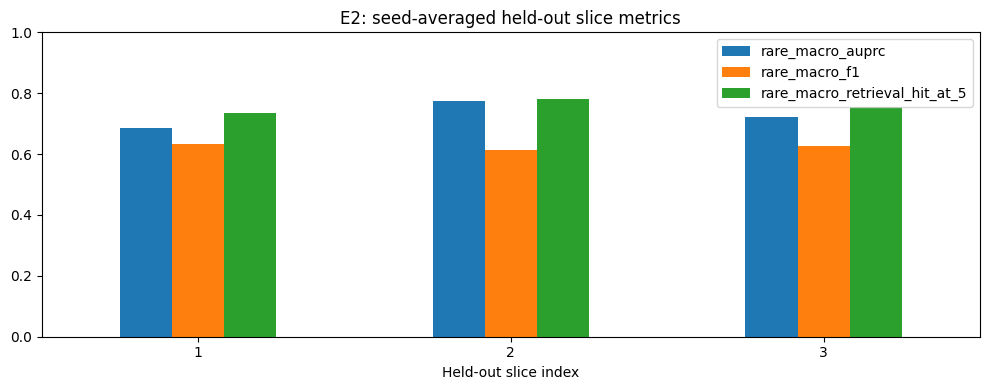

rare_macro_auprc  rare_macro_f1  \
variant         holdout                                    
alpha_0.25      1                0.685492       0.634117   
                2                0.773533       0.612683   
                3                0.721336       0.627207   
alpha_0.75      1                0.685492       0.634117   
                2                0.773533       0.612683   
                3                0.721336       0.627207   
euclidean_only  1                0.676669       0.604925   
                2                0.674566       0.574422   
                3                0.690306       0.603313   
hyperbolic_only 1                0.283869       0.238591   
                2                0.328386       0.230248   
                3                0.297360       0.237321   
main            1                0.685492       0.634117   
                2                0.773533       0.612683   
                3                0.721336       0.627207   

                         rare_macro_retrieval_hit_at_5  \
variant         holdout                                  
alpha_0.25      1                             0.709310   
                2                             0.752238   
                3                             0.733217   
alpha_0.75      1                             0.763934   
                2                             0.782448   
                3                             0.751817   
euclidean_only  1                             0.734738   
                2                             0.743450   
                3                             0.750489   
hyperbolic_only 1                             0.532317   
                2                             0.553754   
                3                             0.530028   
main            1                             0.736501   
                2                             0.781789   
                3                             0.753563   

                         rare_macro_knn_purity_at_5  rare_macro_coverage  \
variant         holdout                                                    
alpha_0.25      1                          0.493905             0.937017   
                2                          0.522897             0.963611   
                3                          0.510930             0.972802   
alpha_0.75      1                          0.579302             0.913873   
                2                          0.604661             0.954964   
                3                          0.603799             0.975340   
euclidean_only  1                          0.566474             0.917823   
                2                          0.584869             0.957742   
                3                          0.601122             0.964193   
hyperbolic_only 1                          0.264931             0.943468   
                2                          0.267561             0.965522   
                3                          0.250088             0.960532   
main            1                          0.546092             0.929851   
                2                          0.578110             0.957851   
                3                          0.573476             0.974745   

                         common_macro_f1  
variant         holdout                   
alpha_0.25      1               0.919991  
                2               0.909925  
                3               0.924598  
alpha_0.75      1               0.919991  
                2               0.909925  
                3               0.924598  
euclidean_only  1               0.882674  
                2               0.880674  
                3               0.897165  
hyperbolic_only 1               0.378664  
                2               0.379038  
                3               0.410206  
main            1               0.919991  
                2               0.909925  
                3               0.92

,holdout,seed,test_near_boundary_fraction,test_ball_radius_fraction_median,test_ball_radius_fraction_std,test_near_mapping_limit_fraction
0,1,42,0.0,0.685219,0.065751,0.0
1,1,0,0.0,0.673795,0.072279,0.0
2,1,1,0.0,0.681745,0.063707,0.0
3,1,2,0.0,0.671007,0.069690,0.0
4,1,3,0.0,0.675983,0.066798,0.0
5,2,42,0.0,0.679153,0.066318,0.0
6,2,0,0.0,0.671189,0.069680,0.0
7,2,1,0.0,0.669547,0.066183,0.0
8,2,2,0.0,0.663635,0.068855,0.0
9,2,3,0.0,0.671692,0.064362,0.0


In [6]:
# 描述性汇总：先在每折内平均 seeds，再展示折间统计。
# 同一组织的留出折有相关性，此标准差不代表独立动物重复的置信区间。
metrics = ["rare_macro_auprc", "rare_macro_f1", "rare_macro_retrieval_hit_at_5",
           "rare_macro_knn_purity_at_5", "rare_macro_coverage", "common_macro_f1"]
by_fold = results.groupby("holdout")[metrics].mean()
display(by_fold)
display(by_fold.agg(["mean", "std"]))
import matplotlib.pyplot as plt
axes = by_fold[["rare_macro_auprc", "rare_macro_f1", "rare_macro_retrieval_hit_at_5"]].plot.bar(
    figsize=(10, 4), ylim=(0, 1), rot=0, title=f"{ARM}: seed-averaged held-out slice metrics")
axes.set_xlabel("Held-out slice index")
plt.tight_layout()
plt.show()

# 冻结编码器诊断：按 variant 与切片汇总，保留全部 seed。
diagnostic_runs = pd.concat([pd.read_csv(
    OUTPUT_ROOT / f"{ARM}_{'pca' if ARM == 'E0' and E0_METHOD == 'pca' else 'ae'}"
    / f"holdout_{h}" / f"seed_{s}" / "diagnostics_summary.csv")
    for h in HOLDOUTS for s in SEEDS], ignore_index=True)
display(diagnostic_runs.groupby(["variant", "holdout"])[metrics].mean())
if ARM != "E0":
    display(results[["holdout", "seed", "test_near_boundary_fraction",
                     "test_ball_radius_fraction_median", "test_ball_radius_fraction_std",
                     "test_near_mapping_limit_fraction"]])


## 三组完成后的配对比较

等 E0/E1/E2 全部完成后，将下一格开关改为 True 再执行。比较器检查协议、输入、预处理、fold/seed 和 AE 参数量，输出 paired delta 与逐类型表。跨切片检索是类型一致性代理，不是真实细胞配对准确率。

In [9]:
COMPARE_WHEN_READY = True
if COMPARE_WHEN_READY:
    from mmdeepspatial.compare import compare_runs
    all_runs, aggregate, all_types = compare_runs(OUTPUT_ROOT, e0_method=E0_METHOD)
    display(aggregate)
    display(all_types[all_types.is_rare].sort_values(["cell_type", "arm", "holdout", "seed"]))


,arm,method,rare_macro_auprc_mean,rare_macro_auprc_std,rare_macro_f1_mean,rare_macro_f1_std,rare_macro_recall_mean,rare_macro_recall_std,rare_macro_coverage_mean,rare_macro_coverage_std,...,common_macro_knn_purity_at_15_mean,common_macro_knn_purity_at_15_std,overall_accuracy_mean,overall_accuracy_std,train_seconds_mean,train_seconds_std,peak_train_gpu_mb_mean,peak_train_gpu_mb_std,test_reconstruction_mse_mean,test_reconstruction_mse_std
0,E0,ae,0.735671,0.046763,0.628003,0.008982,0.804679,0.055445,0.948655,0.021001,...,0.885533,0.008751,0.891718,0.007267,117.394753,59.822754,70.373242,0.042794,0.408359,0.010057
1,E1,ae,0.721448,0.028391,0.632379,0.017039,0.779483,0.032098,0.952340,0.018529,...,0.899615,0.005012,0.898508,0.008829,76.245865,14.175592,70.713086,0.042794,0.476606,0.014154
2,E2,ae,0.726787,0.044273,0.624669,0.010940,0.787733,0.041270,0.954149,0.022675,...,0.858614,0.004071,0.892500,0.007685,95.889937,9.578118,70.588086,0.042794,0.433934,0.012468


,cell_type,train_n,train_fraction,test_n,test_prevalence,predicted_n,is_rare,rarity,train_supported,test_present,...,retrieval_hit_at_15,knn_purity_at_15,coverage_threshold,calibration_n,coverage,coverage_status,arm,method,holdout,seed
17,Endothelial 2,103,0.004525,41,0.007378,70,True,ultra_rare,True,True,...,0.707317,0.250407,0.678906,103,0.95122,ok,E0,ae,1,0
32,Endothelial 2,103,0.004525,41,0.007378,70,True,ultra_rare,True,True,...,0.804878,0.252033,0.713237,103,0.95122,ok,E0,ae,1,1
47,Endothelial 2,103,0.004525,41,0.007378,59,True,ultra_rare,True,True,...,0.756098,0.250407,0.734577,103,0.97561,ok,E0,ae,1,2
62,Endothelial 2,103,0.004525,41,0.007378,65,True,ultra_rare,True,True,...,0.780488,0.292683,0.778884,103,1.00000,ok,E0,ae,1,3
2,Endothelial 2,103,0.004525,41,0.007378,69,True,ultra_rare,True,True,...,0.780488,0.256911,0.657807,103,0.95122,ok,E0,ae,1,42
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
629,Pericytes,152,0.006751,52,0.008961,55,True,ultra_rare,True,True,...,0.942308,0.806410,0.702161,152,1.00000,ok,E2,ae,3,0
644,Pericytes,152,0.006751,52,0.008961,59,True,ultra_rare,True,True,...,0.942308,0.830769,0.719699,152,1.00000,ok,E2,ae,3,1
659,Pericytes,152,0.006751,52,0.008961,61,True,ultra_rare,True,True,...,0.942308,0.825641,0.716438,152,1.00000,ok,E2,ae,3,2
674,Pericytes,152,0.006751,52,0.008961,56,True,ultra_rare,True,True,...,0.961538,0.821795,0.686668,152,1.00000,ok,E2,ae,3,3
